<a href="https://colab.research.google.com/github/NVamshiKRISHNA09/Flood-prediction/blob/flood-prediction/Flood_predction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import pandas as pd
import numpy as np
from flood_risk_model_advanced import predict_df

def score_custom_locations(locations_data):
    """
    Pass list of dictionaries representing locations, or a DataFrame.
    """
    df_input = pd.DataFrame(locations_data)
    # If missing required base risk metrics, populate them with default median score (e.g., 5)
    from flood_risk_model_advanced import BASE_FEATURES
    for col in BASE_FEATURES:
        if col not in df_input.columns:
            df_input[col] = 5

    df_scored = predict_df(df_input)
    return df_scored

custom_locations = [
    {
        "LocationName": "Coastal Suburb Alpha",
        "MonsoonIntensity": 9, "TopographyDrainage": 8, "RiverManagement": 7, "Deforestation": 6,
        "Urbanization": 9, "ClimateChange": 8, "DamsQuality": 3, "Siltation": 8,
        "AgriculturalPractices": 4, "Encroachments": 8, "IneffectiveDisasterPreparedness": 9,
        "DrainageSystems": 2, "CoastalVulnerability": 9, "Landslides": 4, "Watersheds": 3,
        "DeterioratingInfrastructure": 9, "PopulationScore": 8, "WetlandLoss": 7,
        "InadequatePlanning": 9, "PoliticalFactors": 6
    },
    {
        "LocationName": "Highland Valley Beta",
        "MonsoonIntensity": 4, "TopographyDrainage": 3, "RiverManagement": 5, "Deforestation": 2,
        "Urbanization": 2, "ClimateChange": 5, "DamsQuality": 7, "Siltation": 3,
        "AgriculturalPractices": 4, "Encroachments": 2, "IneffectiveDisasterPreparedness": 4,
        "DrainageSystems": 6, "CoastalVulnerability": 1, "Landslides": 7, "Watersheds": 6,
        "DeterioratingInfrastructure": 3, "PopulationScore": 3, "WetlandLoss": 2,
        "InadequatePlanning": 3, "PoliticalFactors": 4
    }
]

scored_output = score_custom_locations(custom_locations)
display(scored_output[["LocationName", "FloodRiskScore", "RiskLevel"]])

,LocationName,FloodRiskScore,RiskLevel
0,Coastal Suburb Alpha,0.6881,Very High
1,Highland Valley Beta,0.3700,Low


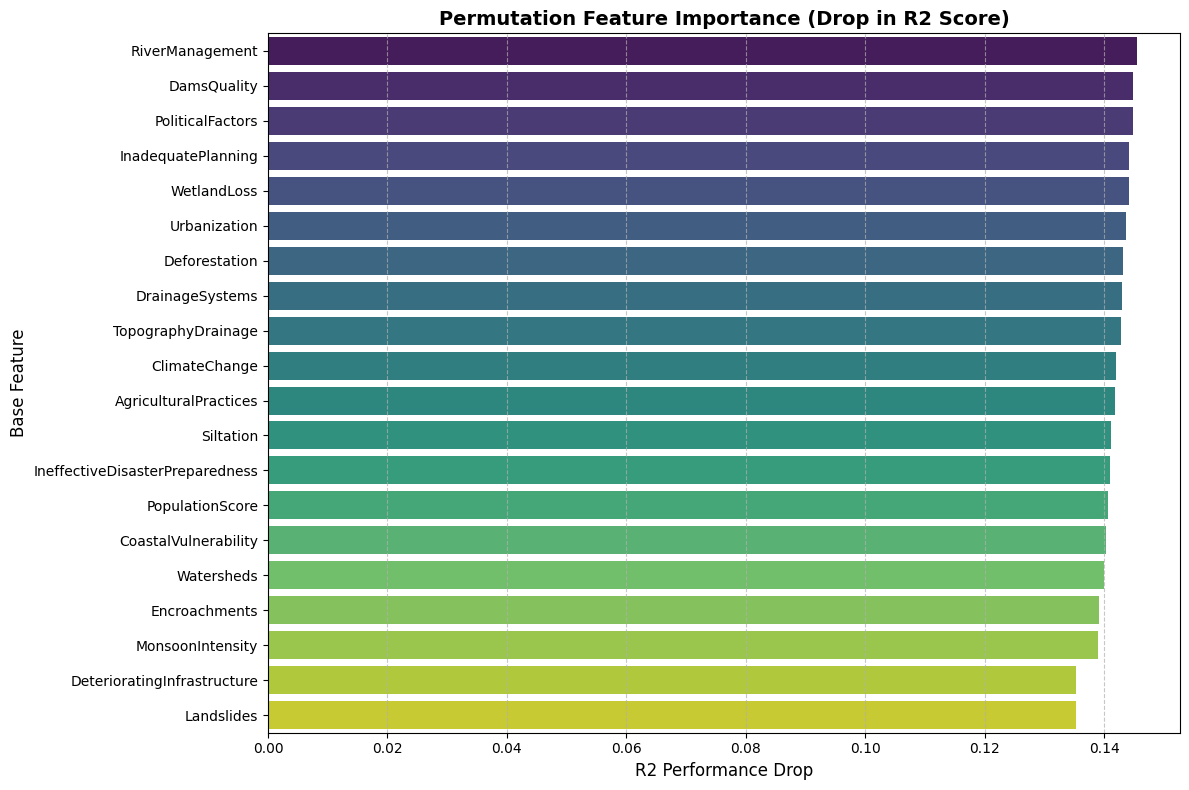

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import joblib
import json
from flood_risk_model_advanced import add_features, load_training_data, BASE_FEATURES

# Load the advanced model and training dataset
bundle = joblib.load('flood_risk_model_advanced.joblib')
meta = json.load(open('flood_risk_meta_advanced.json'))
df_train = load_training_data('/content')

# Prepare the feature matrix X and target y
X = add_features(df_train)
y = df_train['FloodProbability']

# Sample a subset to compute permutation importance efficiently
np.random.seed(42)
sample_idx = np.random.choice(X.index, size=15000, replace=False)
X_sample = X.iloc[sample_idx]
y_sample = y.iloc[sample_idx]

# Evaluate baseline performance on sample
m_ridge = bundle['ridge']
m_gbm = bundle['gbm']
w = bundle['weight']

def predict_ensemble(data):
    return w * m_ridge.predict(data) + (1 - w) * m_gbm.predict(data)

from sklearn.metrics import r2_score
baseline_r2 = r2_score(y_sample, predict_ensemble(X_sample))

# Compute feature importance via permutation on BASE_FEATURES
importances = {}
for feature in BASE_FEATURES:
    X_permuted = X_sample.copy()
    X_permuted[feature] = np.random.permutation(X_permuted[feature].values)
    # Recalculate aggregates so engineered features are also modified correctly
    X_permuted_agg = add_features(X_permuted)
    permuted_r2 = r2_score(y_sample, predict_ensemble(X_permuted_agg))
    importances[feature] = baseline_r2 - permuted_r2

# Convert to DataFrame
fi_df = pd.DataFrame(list(importances.items()), columns=['Feature', 'Importance']).sort_values(by='Importance', ascending=False)

# Plot top features
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=fi_df, palette='viridis', hue='Feature', legend=False)
plt.title('Permutation Feature Importance (Drop in R2 Score)', fontsize=14, fontweight='bold')
plt.xlabel('R2 Performance Drop', fontsize=12)
plt.ylabel('Base Feature', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [26]:
!pip install -q gradio

In [27]:
import gradio as gr
import pandas as pd
import numpy as np
import joblib
import json
from flood_risk_model_advanced import predict_df, BASE_FEATURES

# Dictionary of representative baseline risk factors for key global regions/countries
COUNTRY_PROFILES = {
    "Bangladesh": {"MonsoonIntensity": 9, "TopographyDrainage": 9, "RiverManagement": 8, "Deforestation": 7, "Urbanization": 8, "ClimateChange": 9, "DamsQuality": 3, "Siltation": 9, "AgriculturalPractices": 6, "Encroachments": 8, "IneffectiveDisasterPreparedness": 7, "DrainageSystems": 2, "CoastalVulnerability": 9, "Landslides": 3, "Watersheds": 7, "DeterioratingInfrastructure": 8, "PopulationScore": 9, "WetlandLoss": 8, "InadequatePlanning": 8, "PoliticalFactors": 5},
    "Netherlands": {"MonsoonIntensity": 4, "TopographyDrainage": 2, "RiverManagement": 9, "Deforestation": 2, "Urbanization": 8, "ClimateChange": 8, "DamsQuality": 9, "Siltation": 3, "AgriculturalPractices": 8, "Encroachments": 2, "IneffectiveDisasterPreparedness": 9, "DrainageSystems": 9, "CoastalVulnerability": 9, "Landslides": 1, "Watersheds": 8, "DeterioratingInfrastructure": 9, "PopulationScore": 7, "WetlandLoss": 3, "InadequatePlanning": 9, "PoliticalFactors": 8},
    "United States": {"MonsoonIntensity": 5, "TopographyDrainage": 5, "RiverManagement": 6, "Deforestation": 4, "Urbanization": 7, "ClimateChange": 7, "DamsQuality": 6, "Siltation": 5, "AgriculturalPractices": 5, "Encroachments": 5, "IneffectiveDisasterPreparedness": 7, "DrainageSystems": 6, "CoastalVulnerability": 6, "Landslides": 4, "Watersheds": 6, "DeterioratingInfrastructure": 6, "PopulationScore": 6, "WetlandLoss": 5, "InadequatePlanning": 6, "PoliticalFactors": 6},
    "Brazil": {"MonsoonIntensity": 8, "TopographyDrainage": 6, "RiverManagement": 5, "Deforestation": 9, "Urbanization": 7, "ClimateChange": 8, "DamsQuality": 5, "Siltation": 6, "AgriculturalPractices": 7, "Encroachments": 6, "IneffectiveDisasterPreparedness": 5, "DrainageSystems": 4, "CoastalVulnerability": 5, "Landslides": 7, "Watersheds": 8, "DeterioratingInfrastructure": 5, "PopulationScore": 7, "WetlandLoss": 7, "InadequatePlanning": 7, "PoliticalFactors": 5},
    "Egypt": {"MonsoonIntensity": 2, "TopographyDrainage": 3, "RiverManagement": 7, "Deforestation": 1, "Urbanization": 6, "ClimateChange": 6, "DamsQuality": 7, "Siltation": 4, "AgriculturalPractices": 5, "Encroachments": 3, "IneffectiveDisasterPreparedness": 6, "DrainageSystems": 4, "CoastalVulnerability": 4, "Landslides": 1, "Watersheds": 4, "DeterioratingInfrastructure": 5, "PopulationScore": 8, "WetlandLoss": 2, "InadequatePlanning": 6, "PoliticalFactors": 5},
    "Japan": {"MonsoonIntensity": 7, "TopographyDrainage": 6, "RiverManagement": 8, "Deforestation": 3, "Urbanization": 8, "ClimateChange": 7, "DamsQuality": 8, "Siltation": 4, "AgriculturalPractices": 7, "Encroachments": 4, "IneffectiveDisasterPreparedness": 9, "DrainageSystems": 8, "CoastalVulnerability": 8, "Landslides": 8, "Watersheds": 7, "DeterioratingInfrastructure": 8, "PopulationScore": 8, "WetlandLoss": 4, "InadequatePlanning": 8, "PoliticalFactors": 8},
    "Default (Average Country)": {feat: 5 for feat in BASE_FEATURES}
}

def predict_country_flood_risk(country_name, *slider_values):
    # Extract current parameters from manual adjustments or selected country
    inputs = {BASE_FEATURES[i]: slider_values[i] for i in range(len(BASE_FEATURES))}
    df = pd.DataFrame([inputs])

    # Generate prediction
    prediction_df = predict_df(df)
    score = float(prediction_df["FloodRiskScore"].iloc[0])
    level = str(prediction_df["RiskLevel"].iloc[0])

    # Color code risk
    emoji = "❌ Very High" if level == "Very High" else "⚠️ High" if level == "High" else "☑️ Moderate" if level == "Moderate" else "✅ Low"

    return f"## predicted Flood Probability: {score:.2%}", f"### Risk Category: {emoji}"

def load_profile(country):
    profile = COUNTRY_PROFILES.get(country, COUNTRY_PROFILES["Default (Average Country)"])
    return [profile[feat] for feat in BASE_FEATURES]

# Create Custom Gradio Dashboard
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🌊 Global Flood Risk-Scoring Web Portal")
    gr.Markdown("Select a country to load preset profiles or dynamically tune factors using the control board sliders below.")

    with gr.Row():
        country_dropdown = gr.Dropdown(
            choices=list(COUNTRY_PROFILES.keys()),
            value="Default (Average Country)",
            label="Choose Country Profile"
        )

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### Prediction Results")
            prob_output = gr.Markdown("## Predicted Flood Probability: --%")
            level_output = gr.Markdown("### Risk Category: --")
            predict_btn = gr.Button("Recalculate Risk Score", variant="primary")

        with gr.Column(scale=2):
            gr.Markdown("### Parameter Adjustments (Scale: 1-10)")
            sliders = []
            # Group sliders into manageable sections
            for feature in BASE_FEATURES:
                sliders.append(gr.Slider(minimum=0, maximum=10, step=1, value=5, label=feature))

    country_dropdown.change(fn=load_profile, inputs=country_dropdown, outputs=sliders)
    predict_btn.click(fn=predict_country_flood_risk, inputs=[country_dropdown] + sliders, outputs=[prob_output, level_output])

# Launch portal as local web server in Colab
demo.launch(inline=True, share=True)

/tmp/ipykernel_2199/697191940.py:39: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://26f34978b9d8f949cd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
